# LAB 3 - Bài 5 (Trang 29): Gom cụm khối u lành tính / ác tính (WDBC)
Hồng Kim Dung - 6451071009

**Lưu ý:** upload file `wdbc.data` lên Colab trước khi chạy.

## Đọc dữ liệu WDBC

In [1]:
print("Hồng Kim Dung - 6451071009")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Upload file wdbc.data lên Colab (biểu tượng thư mục bên trái) trước khi chạy.
# File không có dòng tiêu đề: cột 1 = ID, cột 2 = chẩn đoán (M/B), 30 cột còn lại là đặc trưng.
dac_trung = ["radius", "texture", "perimeter", "area", "smoothness",
             "compactness", "concavity", "concave points", "symmetry", "fractal dimension"]
ten_cot = ["ID", "Diagnosis"]
for hau_to in ["mean", "se", "worst"]:
    ten_cot += [f"{t} ({hau_to})" for t in dac_trung]

data = pd.read_csv("wdbc.data", header=None, names=ten_cot)
print(data.shape)
print(data.head())

Hồng Kim Dung - 6451071009
(569, 32)
         ID Diagnosis  radius (mean)  texture (mean)  perimeter (mean)  \
0    842302         M          17.99           10.38            122.80   
1    842517         M          20.57           17.77            132.90   
2  84300903         M          19.69           21.25            130.00   
3  84348301         M          11.42           20.38             77.58   
4  84358402         M          20.29           14.34            135.10   

   area (mean)  smoothness (mean)  compactness (mean)  concavity (mean)  \
0       1001.0            0.11840             0.27760            0.3001   
1       1326.0            0.08474             0.07864            0.0869   
2       1203.0            0.10960             0.15990            0.1974   
3        386.1            0.14250             0.28390            0.2414   
4       1297.0            0.10030             0.13280            0.1980   

   concave points (mean)  ...  radius (worst)  texture (worst)  \
0

## Khảo sát dữ liệu

In [2]:
print("Hồng Kim Dung - 6451071009")
print(data.isnull().sum().sum(), "giá trị thiếu")
print(data["Diagnosis"].value_counts())    # B = lành tính (benign), M = ác tính (malignant)

X = data.drop(columns=["ID", "Diagnosis"])
y = data["Diagnosis"].map({"B": 0, "M": 1}).values     # nhãn thật, chỉ dùng để so sánh sau khi gom cụm
print("X:", X.shape)

Hồng Kim Dung - 6451071009
0 giá trị thiếu
Diagnosis
B    357
M    212
Name: count, dtype: int64
X: (569, 30)


## Chuẩn hóa dữ liệu

In [3]:
print("Hồng Kim Dung - 6451071009")
from sklearn.preprocessing import StandardScaler

# Các thuộc tính có thang đo rất khác nhau (area ~ hàng trăm, smoothness ~ 0.1),
# nên cần chuẩn hóa trước khi gom cụm.
X_scaled = StandardScaler().fit_transform(X)
print("Mean:", X_scaled.mean().round(4), "| Std:", X_scaled.std().round(4))

Hồng Kim Dung - 6451071009
Mean: -0.0 | Std: 1.0


## Elbow method và Silhouette để chọn số cụm

Hồng Kim Dung - 6451071009


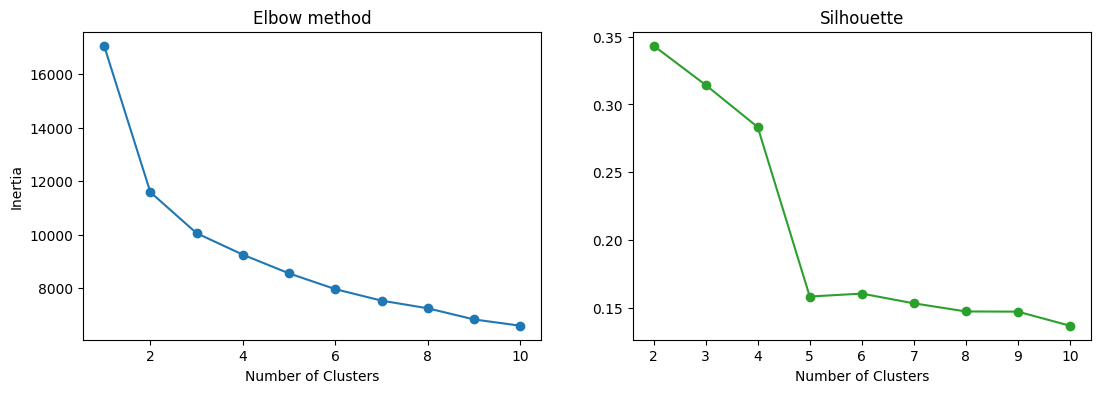

Silhouette k = 2: 0.34338224069077805


In [4]:
print("Hồng Kim Dung - 6451071009")
from sklearn.cluster import KMeans
from sklearn import metrics

inertia, sil = [], []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)
    if k > 1:
        sil.append(metrics.silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(range(1, 11), inertia, "o-")
ax[0].set_title("Elbow method"); ax[0].set_xlabel("Number of Clusters"); ax[0].set_ylabel("Inertia")
ax[1].plot(range(2, 11), sil, "o-", color="tab:green")
ax[1].set_title("Silhouette"); ax[1].set_xlabel("Number of Clusters")
plt.show()
print("Silhouette k = 2:", sil[0])

## Gom cụm bằng k-Means với k = 2 (lành tính / ác tính)

In [5]:
print("Hồng Kim Dung - 6451071009")
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(X_scaled)

print("Số mẫu mỗi cụm:")
print(pd.Series(cluster_labels).value_counts().sort_index())

Hồng Kim Dung - 6451071009
Số mẫu mỗi cụm:
0    375
1    194
Name: count, dtype: int64


## So sánh cụm với chẩn đoán thật

Hồng Kim Dung - 6451071009
Chẩn đoán thật    B    M
Cụm                     
0               339   36
1                18  176
Cụm -> chẩn đoán chiếm đa số: {0: 'B', 1: 'M'}
Accuracy: 0.9050966608084359
               precision    recall  f1-score   support

   Benign (B)     0.9040    0.9496    0.9262       357
Malignant (M)     0.9072    0.8302    0.8670       212

     accuracy                         0.9051       569
    macro avg     0.9056    0.8899    0.8966       569
 weighted avg     0.9052    0.9051    0.9042       569



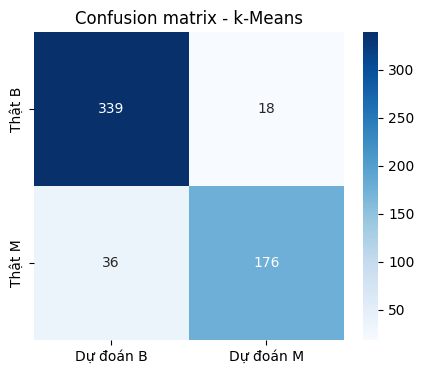

In [6]:
print("Hồng Kim Dung - 6451071009")
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

bang = pd.crosstab(cluster_labels, data["Diagnosis"], rownames=["Cụm"], colnames=["Chẩn đoán thật"])
print(bang)

# Gán nhãn cho mỗi cụm theo chẩn đoán chiếm đa số trong cụm đó
cum_ten = {c: bang.loc[c].idxmax() for c in bang.index}
print("Cụm -> chẩn đoán chiếm đa số:", cum_ten)
y_pred = np.array([0 if cum_ten[c] == "B" else 1 for c in cluster_labels])

print("Accuracy:", accuracy_score(y, y_pred))
print(classification_report(y, y_pred, target_names=["Benign (B)", "Malignant (M)"], digits=4))

cm = confusion_matrix(y, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Dự đoán B", "Dự đoán M"], yticklabels=["Thật B", "Thật M"])
plt.title("Confusion matrix - k-Means")
plt.show()

## Các độ đo đánh giá gom cụm

In [7]:
print("Hồng Kim Dung - 6451071009")
print("Silhouette coefficient         :", metrics.silhouette_score(X_scaled, cluster_labels))
print("Adjusted Rand Index (ARI)      :", metrics.adjusted_rand_score(y, cluster_labels))
print("Normalized Mutual Info (NMI)   :", metrics.normalized_mutual_info_score(y, cluster_labels))
print("Homogeneity                    :", metrics.homogeneity_score(y, cluster_labels))
print("Completeness                   :", metrics.completeness_score(y, cluster_labels))

Hồng Kim Dung - 6451071009
Silhouette coefficient         : 0.34338224069077805
Adjusted Rand Index (ARI)      : 0.6536246043910179
Normalized Mutual Info (NMI)   : 0.5324078598532422
Homogeneity                    : 0.5248878197516513
Completeness                   : 0.5401465104108913


## Biểu diễn kết quả gom cụm trên mặt phẳng 2D (PCA)

Hồng Kim Dung - 6451071009
Tỉ lệ phương sai giữ lại: 0.6324320765155944


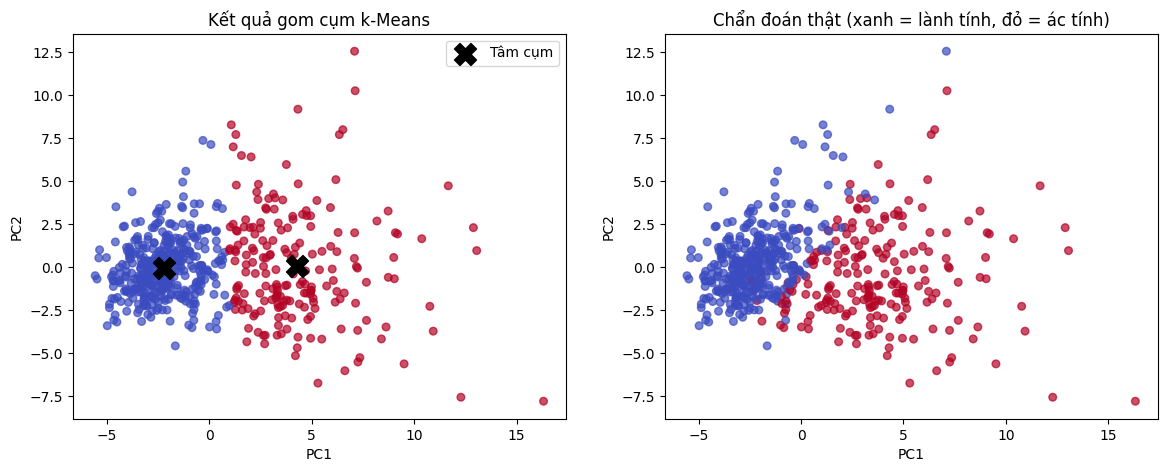

In [8]:
print("Hồng Kim Dung - 6451071009")
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)
print("Tỉ lệ phương sai giữ lại:", pca.explained_variance_ratio_.sum())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(X_2d[:, 0], X_2d[:, 1], c=cluster_labels, cmap="coolwarm", s=30, alpha=0.7)
c2d = pca.transform(kmeans.cluster_centers_)
ax[0].scatter(c2d[:, 0], c2d[:, 1], c="black", marker="X", s=250, label="Tâm cụm")
ax[0].set_title("Kết quả gom cụm k-Means"); ax[0].legend()

ax[1].scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap="coolwarm", s=30, alpha=0.7)
ax[1].set_title("Chẩn đoán thật (xanh = lành tính, đỏ = ác tính)")
for a in ax:
    a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.show()